Name: Ivy Cheng

Github Username: ivychengusc

USC ID: 6931463618

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.model_selection import GridSearchCV, cross_val_score
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression, RidgeCV, LassoCV
from sklearn.metrics import mean_squared_error
from sklearn.decomposition import PCA
from sklearn.pipeline import Pipeline

import xgboost as xgb

## 1(b)

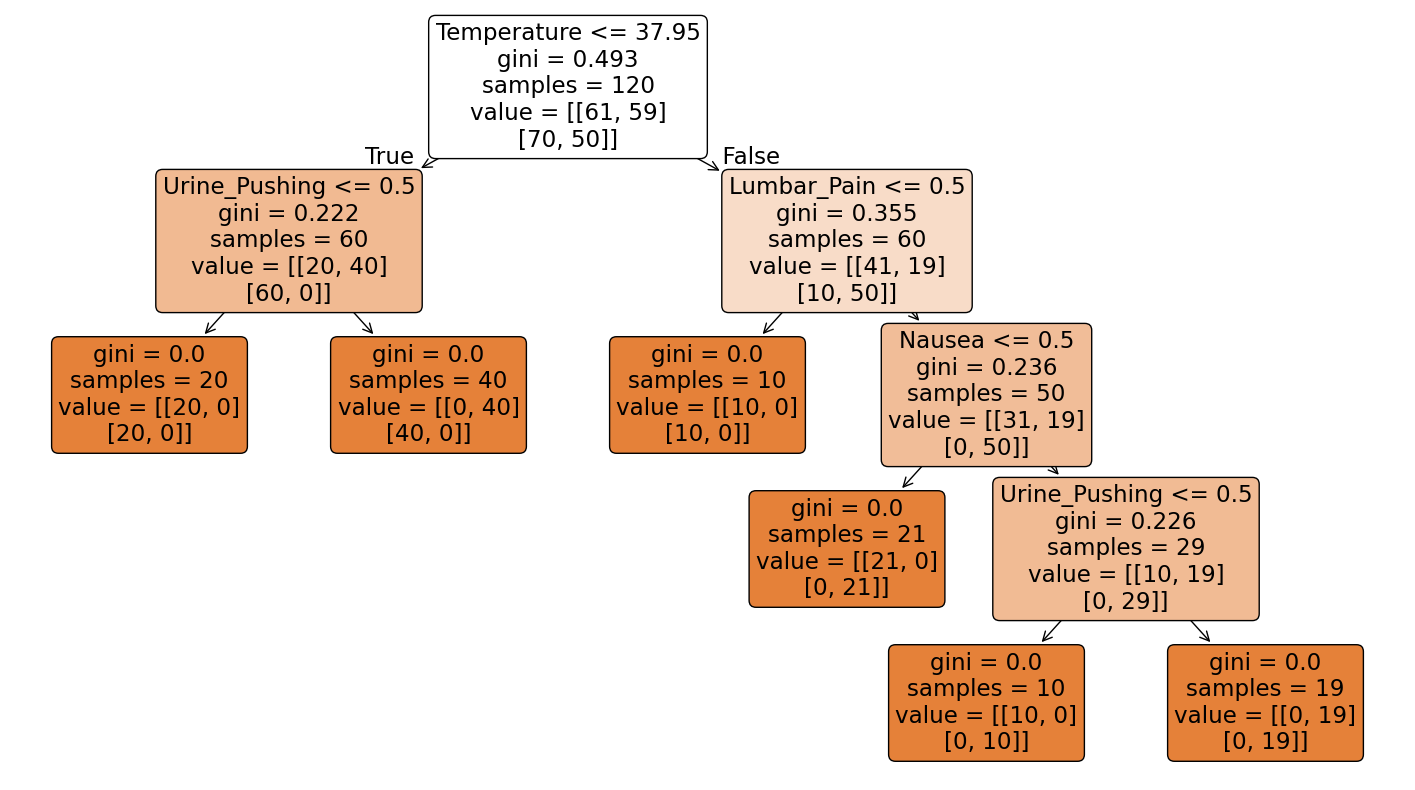

In [2]:
from pathlib import Path

DATA_PATH = Path("..") / "data" / "Homework 5 Data"

columns = [
    "Temperature",
    "Nausea",
    "Lumbar_Pain",
    "Urine_Pushing",
    "Micturition_Pains",
    "Burning_Urethra",
    "Inflammation_Bladder",
    "Nephritis"
]

df = pd.read_csv(
    DATA_PATH / "diagnosis.data",
    sep="\t",
    header=None,
    names=columns,
    encoding="utf-16"
)

df["Temperature"] = (
    df["Temperature"]
    .str.replace(",", ".", regex=False)
    .astype(float)
)

df = df.replace({"yes": 1, "no": 0})

X = df.iloc[:, :-2]
y = df.iloc[:, -2:]

clf = DecisionTreeClassifier(random_state=42)
clf.fit(X, y)

plt.figure(figsize=(18, 10))
plot_tree(
    clf,
    feature_names=X.columns,
    filled=True,
    rounded=True
)
plt.show()

## 1(c)

In [3]:
rules = export_text(
    clf,
    feature_names=list(X.columns)
)

print(rules)

|--- Temperature <= 37.95
|   |--- Urine_Pushing <= 0.50
|   |   |--- class: 0
|   |--- Urine_Pushing >  0.50
|   |   |--- class: 1
|--- Temperature >  37.95
|   |--- Lumbar_Pain <= 0.50
|   |   |--- class: 0
|   |--- Lumbar_Pain >  0.50
|   |   |--- Nausea <= 0.50
|   |   |   |--- class: 0
|   |   |--- Nausea >  0.50
|   |   |   |--- Urine_Pushing <= 0.50
|   |   |   |   |--- class: 0
|   |   |   |--- Urine_Pushing >  0.50
|   |   |   |   |--- class: 0



In [4]:
from sklearn.tree import _tree

def tree_to_rules(tree, feature_names):
    tree_ = tree.tree_
    feature_name = [
        feature_names[i] if i != _tree.TREE_UNDEFINED else "undefined!"
        for i in tree_.feature
    ]

    rules = []

    def recurse(node, conditions):
        if tree_.feature[node] != _tree.TREE_UNDEFINED:
            name = feature_name[node]
            threshold = tree_.threshold[node]

            recurse(
                tree_.children_left[node],
                conditions + [f"{name} <= {threshold:.2f}"]
            )

            recurse(
                tree_.children_right[node],
                conditions + [f"{name} > {threshold:.2f}"]
            )
        else:
            prediction = tree_.value[node][0]
            rules.append((conditions, prediction))

    recurse(0, [])
    return rules

In [5]:
rules = tree_to_rules(clf, list(X.columns))

for i, (conditions, prediction) in enumerate(rules, 1):
    print(f"Rule {i}:")
    print("IF " + " AND ".join(conditions))
    print("THEN", prediction)
    print()

Rule 1:
IF Temperature <= 37.95 AND Urine_Pushing <= 0.50
THEN [1. 0.]

Rule 2:
IF Temperature <= 37.95 AND Urine_Pushing > 0.50
THEN [0. 1.]

Rule 3:
IF Temperature > 37.95 AND Lumbar_Pain <= 0.50
THEN [1. 0.]

Rule 4:
IF Temperature > 37.95 AND Lumbar_Pain > 0.50 AND Nausea <= 0.50
THEN [1. 0.]

Rule 5:
IF Temperature > 37.95 AND Lumbar_Pain > 0.50 AND Nausea > 0.50 AND Urine_Pushing <= 0.50
THEN [1. 0.]

Rule 6:
IF Temperature > 37.95 AND Lumbar_Pain > 0.50 AND Nausea > 0.50 AND Urine_Pushing > 0.50
THEN [0. 1.]



## 1(d)

In [6]:
path = clf.cost_complexity_pruning_path(X, y)
ccp_alphas = path.ccp_alphas

cv_scores = []

for alpha in ccp_alphas:
    tree = DecisionTreeClassifier(
        random_state=42,
        ccp_alpha=alpha
    )

    scores = cross_val_score(
        tree,
        X,
        y,
        cv=5
    )

    cv_scores.append(scores.mean())

best_alpha = ccp_alphas[np.argmax(cv_scores)]

print("Best ccp_alpha:", best_alpha)
print("Best CV score:", max(cv_scores))

Best ccp_alpha: 0.0
Best CV score: 0.95


In [7]:
pruned_clf = DecisionTreeClassifier(
    random_state=42,
    ccp_alpha=best_alpha
)

pruned_clf.fit(X, y)

print("Number of nodes:", pruned_clf.tree_.node_count)
print("Tree depth:", pruned_clf.tree_.max_depth)

Number of nodes: 11
Tree depth: 4


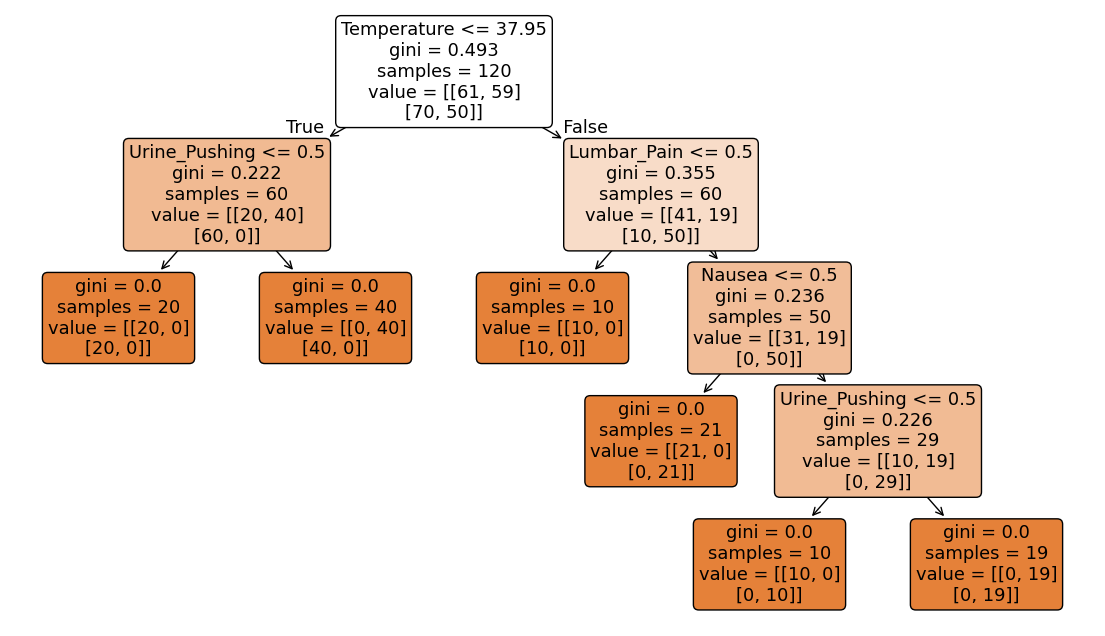

In [8]:
plt.figure(figsize=(14, 8))

plot_tree(
    pruned_clf,
    feature_names=X.columns,
    filled=True,
    rounded=True
)

plt.show()

In [9]:
pruned_rules = export_text(
    pruned_clf,
    feature_names=list(X.columns)
)

print(pruned_rules)

|--- Temperature <= 37.95
|   |--- Urine_Pushing <= 0.50
|   |   |--- class: 0
|   |--- Urine_Pushing >  0.50
|   |   |--- class: 1
|--- Temperature >  37.95
|   |--- Lumbar_Pain <= 0.50
|   |   |--- class: 0
|   |--- Lumbar_Pain >  0.50
|   |   |--- Nausea <= 0.50
|   |   |   |--- class: 0
|   |   |--- Nausea >  0.50
|   |   |   |--- Urine_Pushing <= 0.50
|   |   |   |   |--- class: 0
|   |   |   |--- Urine_Pushing >  0.50
|   |   |   |   |--- class: 0



Rule 1:
IF Temperature <= 37.95 AND Urine_Pushing = no
THEN Inflammation_Bladder = no AND Nephritis = no

Rule 2:
IF Temperature <= 37.95 AND Urine_Pushing = yes
THEN Inflammation_Bladder = yes AND Nephritis = no

Rule 3:
IF Temperature > 37.95 AND Lumbar_Pain = no
THEN Inflammation_Bladder = no AND Nephritis = no

Rule 4:
IF Temperature > 37.95 AND Lumbar_Pain = yes AND Nausea = no
THEN Inflammation_Bladder = no AND Nephritis = yes

Rule 5:
IF Temperature > 37.95 AND Lumbar_Pain = yes AND Nausea = yes
AND Urine_Pushing = no
THEN Inflammation_Bladder = no AND Nephritis = yes

Rule 6:
IF Temperature > 37.95 AND Lumbar_Pain = yes AND Nausea = yes
AND Urine_Pushing = yes
THEN Inflammation_Bladder = yes AND Nephritis = yes

## 2(a)

In [10]:
attribute_names = []

with open(
    DATA_PATH / "communities.names",
    "r",
    encoding="latin1"
) as file:
    
    for line in file:
        line = line.strip()
        
        if line.startswith("@attribute"):
            attribute_names.append(
                line.split()[1]
            )

crime_df = pd.read_csv(
    DATA_PATH / "communities.data",
    header=None,
    names=attribute_names,
    na_values="?"
)

train_df = crime_df.iloc[:1495].copy()
test_df = crime_df.iloc[1495:].copy()

print("Training set shape:", train_df.shape)
print("Test set shape:", test_df.shape)

Training set shape: (1495, 128)
Test set shape: (499, 128)


## 2(b)

In [11]:
non_predictive = [
    "state",
    "county",
    "community",
    "communityname",
    "fold"
]

target = "ViolentCrimesPerPop"

X_train = train_df.drop(
    columns=non_predictive + [target]
)

y_train = train_df[target]

X_test = test_df.drop(
    columns=non_predictive + [target]
)

y_test = test_df[target]

print("Number of predictors:", X_train.shape[1])

print(
    "Missing values in training set:",
    X_train.isna().sum().sum()
)

print(
    "Missing values in test set:",
    X_test.isna().sum().sum()
)

Number of predictors: 122
Missing values in training set: 27633
Missing values in test set: 9218


In [12]:
imputer = SimpleImputer(
    strategy="median"
)

X_train_imputed = pd.DataFrame(
    imputer.fit_transform(X_train),
    columns=X_train.columns,
    index=X_train.index
)

X_test_imputed = pd.DataFrame(
    imputer.transform(X_test),
    columns=X_test.columns,
    index=X_test.index
)

X_train = X_train_imputed
X_test = X_test_imputed

In [13]:
print(
    "Missing values in training set:",
    X_train.isna().sum().sum()
)

print(
    "Missing values in test set:",
    X_test.isna().sum().sum()
)

print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)

Missing values in training set: 0
Missing values in test set: 0
X_train shape: (1495, 122)
X_test shape: (499, 122)


I removed the five non-predictive features listed in the data description and used median imputation to replace the missing values. The imputer was fitted using only the training data and then applied to the test data.

## 2(c)

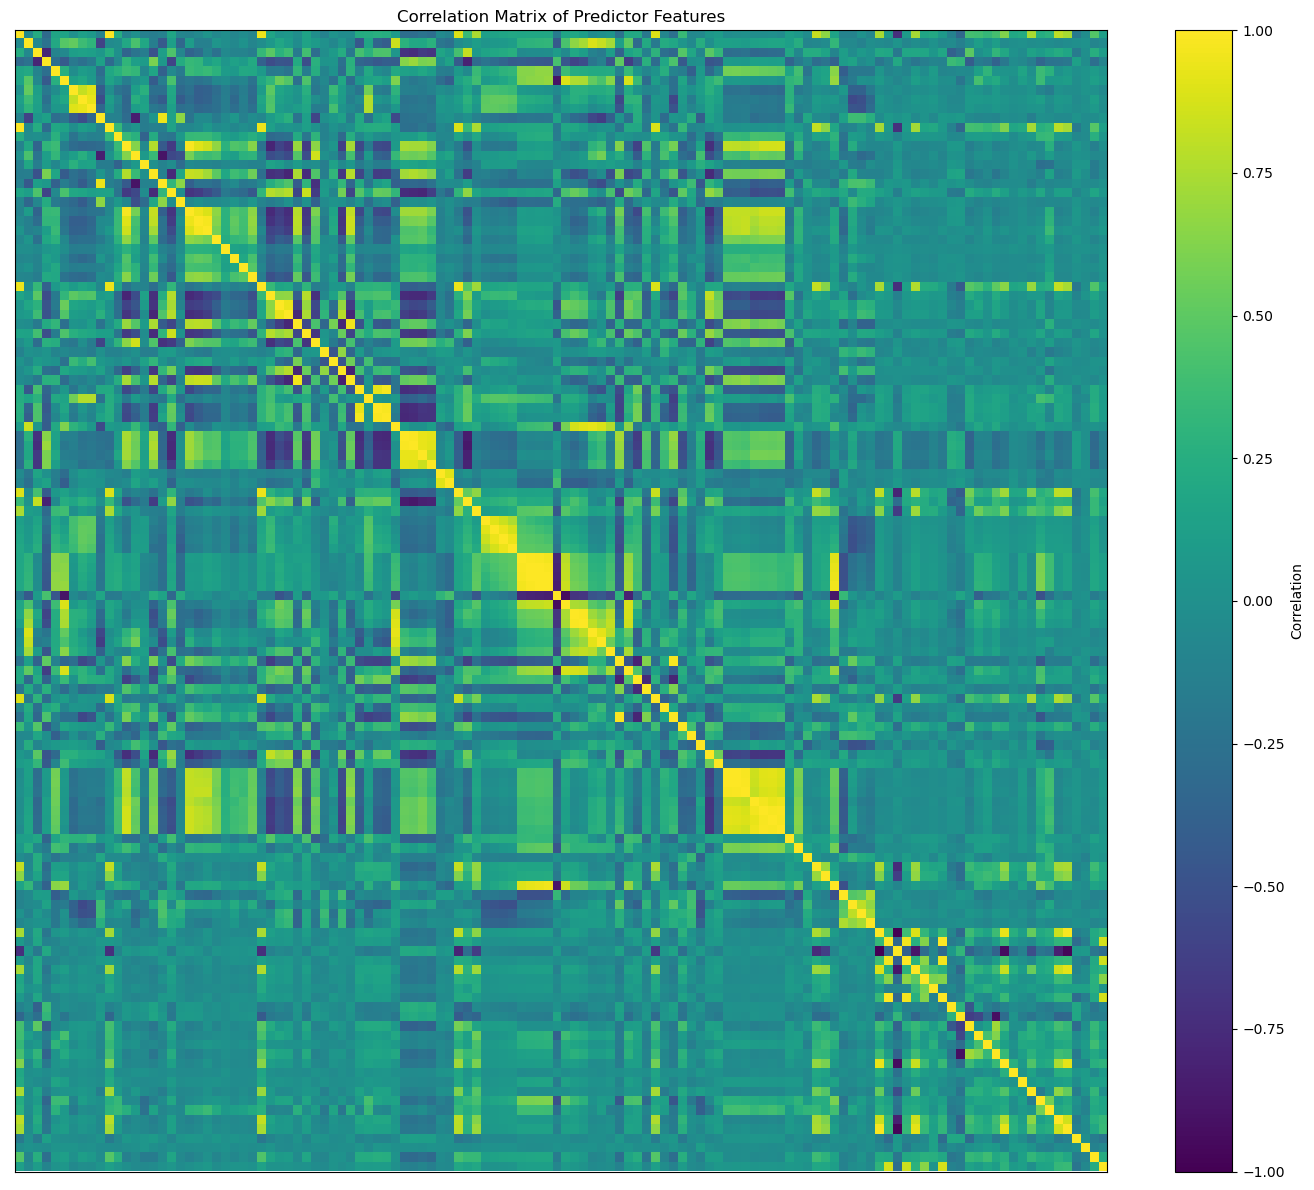

In [14]:
correlation_matrix = X_train.corr()

plt.figure(figsize=(14, 12))

plt.imshow(
    correlation_matrix,
    aspect='auto',
    vmin=-1,
    vmax=1
)

plt.colorbar(
    label='Correlation'
)

plt.title(
    'Correlation Matrix of Predictor Features'
)

plt.xticks([])
plt.yticks([])

plt.tight_layout()
plt.show()

## 2(d)

In [15]:
feature_means = X_train.mean()

feature_stds = X_train.std(
    ddof=1
)

cv_values = (
    feature_stds
    / feature_means
)

cv_table = pd.DataFrame({
    'Mean': feature_means,
    'Standard Deviation': feature_stds,
    'CV': cv_values
})

cv_table = cv_table.sort_values(
    by='CV',
    ascending=False
)

cv_table

,Mean,Standard Deviation,CV
PctPolicAsian,0.016254,0.089838,5.527059
NumStreet,0.022983,0.098665,4.292923
NumInShelters,0.029599,0.102736,3.470952
NumIlleg,0.037204,0.113806,3.058964
NumImmig,0.030595,0.089541,2.926635
...,...,...,...
NumKindsDrugsSeiz,0.567130,0.079977,0.141021
RacialMatchCommPol,0.722375,0.093657,0.129652
PctPolicWhite,0.762856,0.090572,0.118727
LemasPctPolicOnPatr,0.752495,0.084304,0.112032


In [16]:
print(
    "Features with mean = 0:",
    (feature_means == 0).sum()
)

Features with mean = 0: 0


## 2(e)

In [17]:
num_features = int(
    np.floor(
        np.sqrt(128)
    )
)

top_cv_features = cv_table.head(
    num_features
).index.tolist()

print(
    "Number of selected features:",
    num_features
)

print(
    "Selected features:"
)

for feature in top_cv_features:
    print(feature)

Number of selected features: 11
Selected features:
PctPolicAsian
NumStreet
NumInShelters
NumIlleg
NumImmig
LemasPctOfficDrugUn
NumUnderPov
LemasSwornFT
population
numbUrban
HousVacant


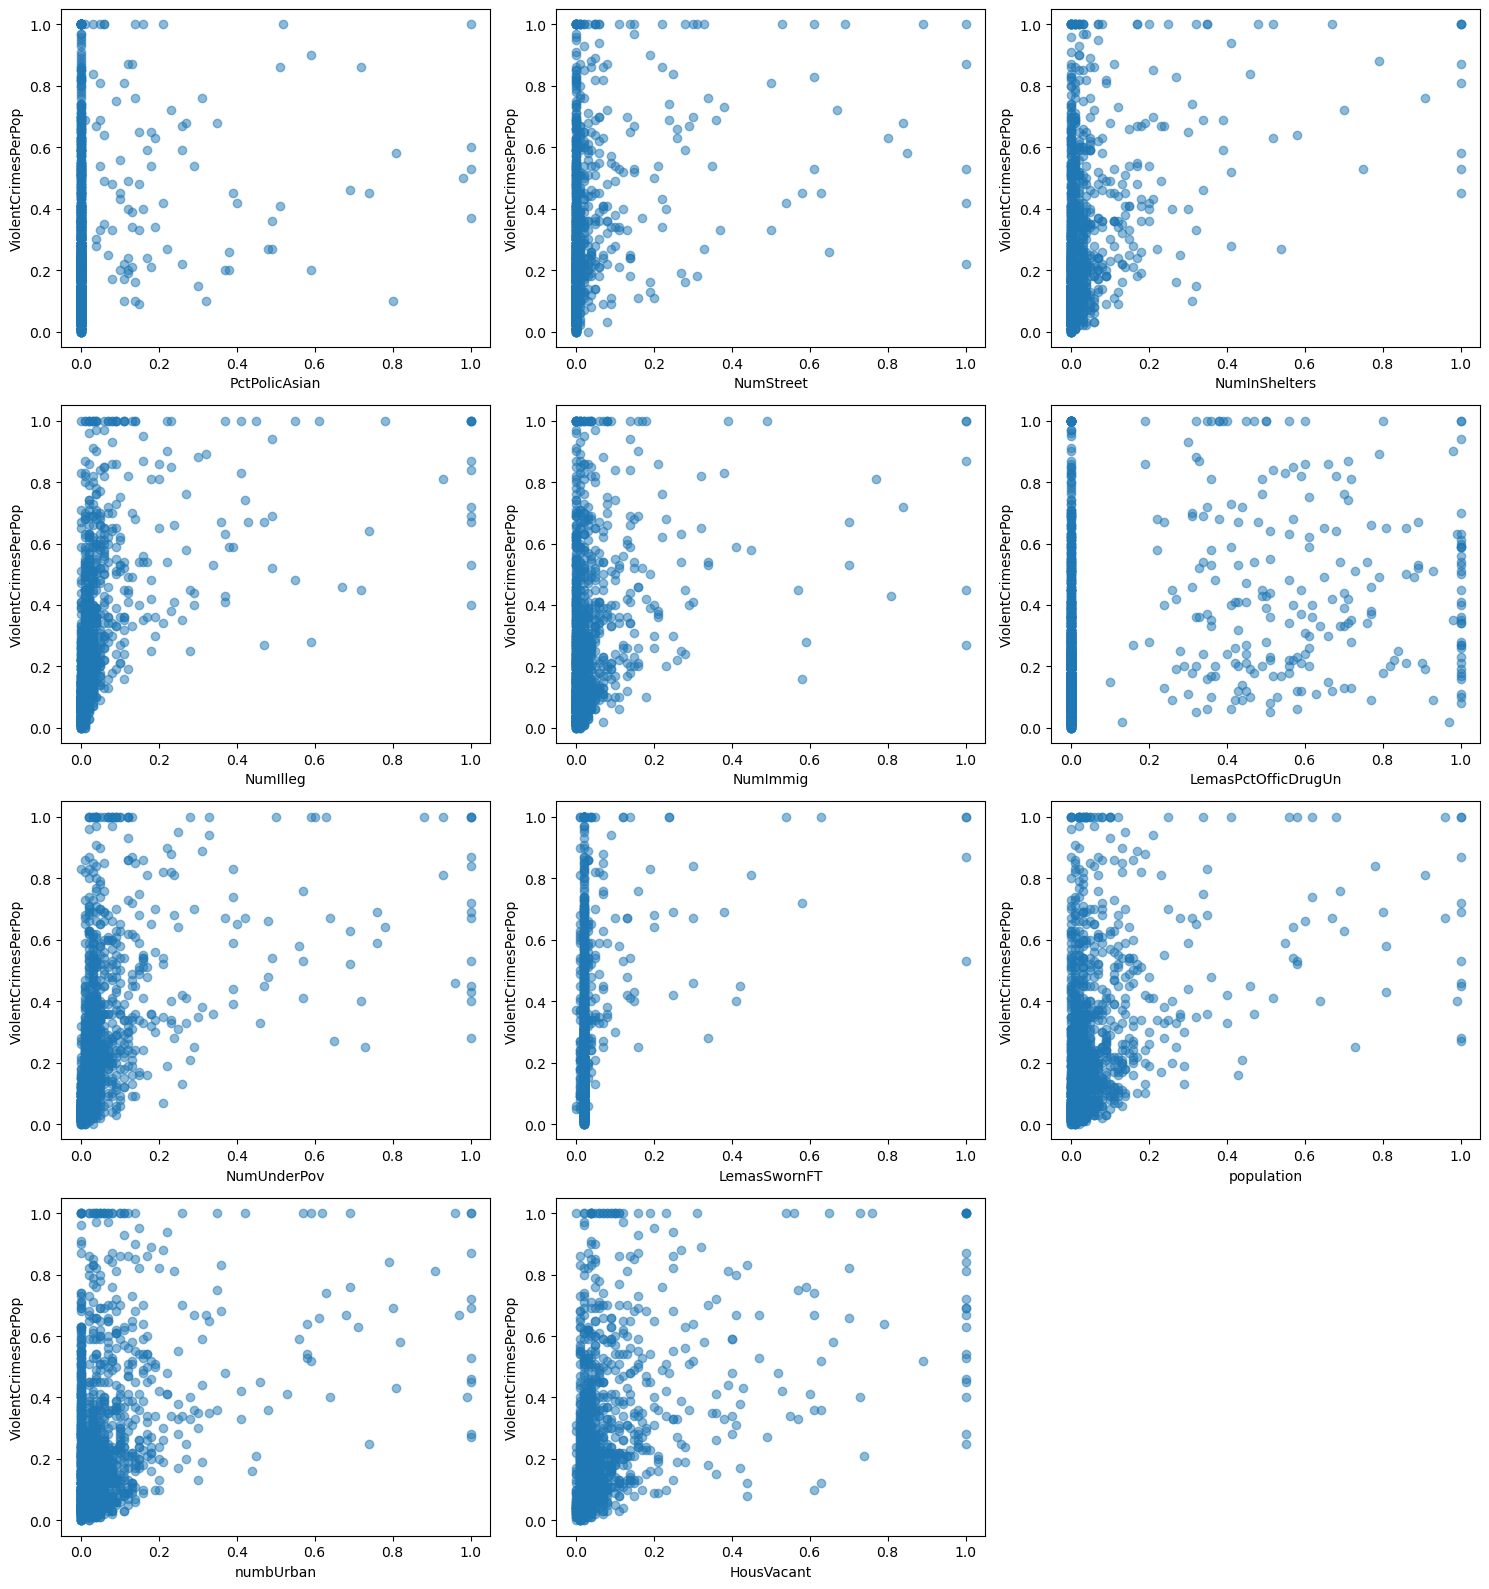

In [18]:
fig, axes = plt.subplots(
    4,
    3,
    figsize=(15, 16)
)

axes = axes.flatten()

for i, feature in enumerate(
    top_cv_features
):
    
    axes[i].scatter(
        X_train[feature],
        y_train,
        alpha=0.5
    )
    
    axes[i].set_xlabel(
        feature
    )
    
    axes[i].set_ylabel(
        'ViolentCrimesPerPop'
    )

for i in range(
    len(top_cv_features),
    len(axes)
):
    axes[i].axis('off')

plt.tight_layout()
plt.show()

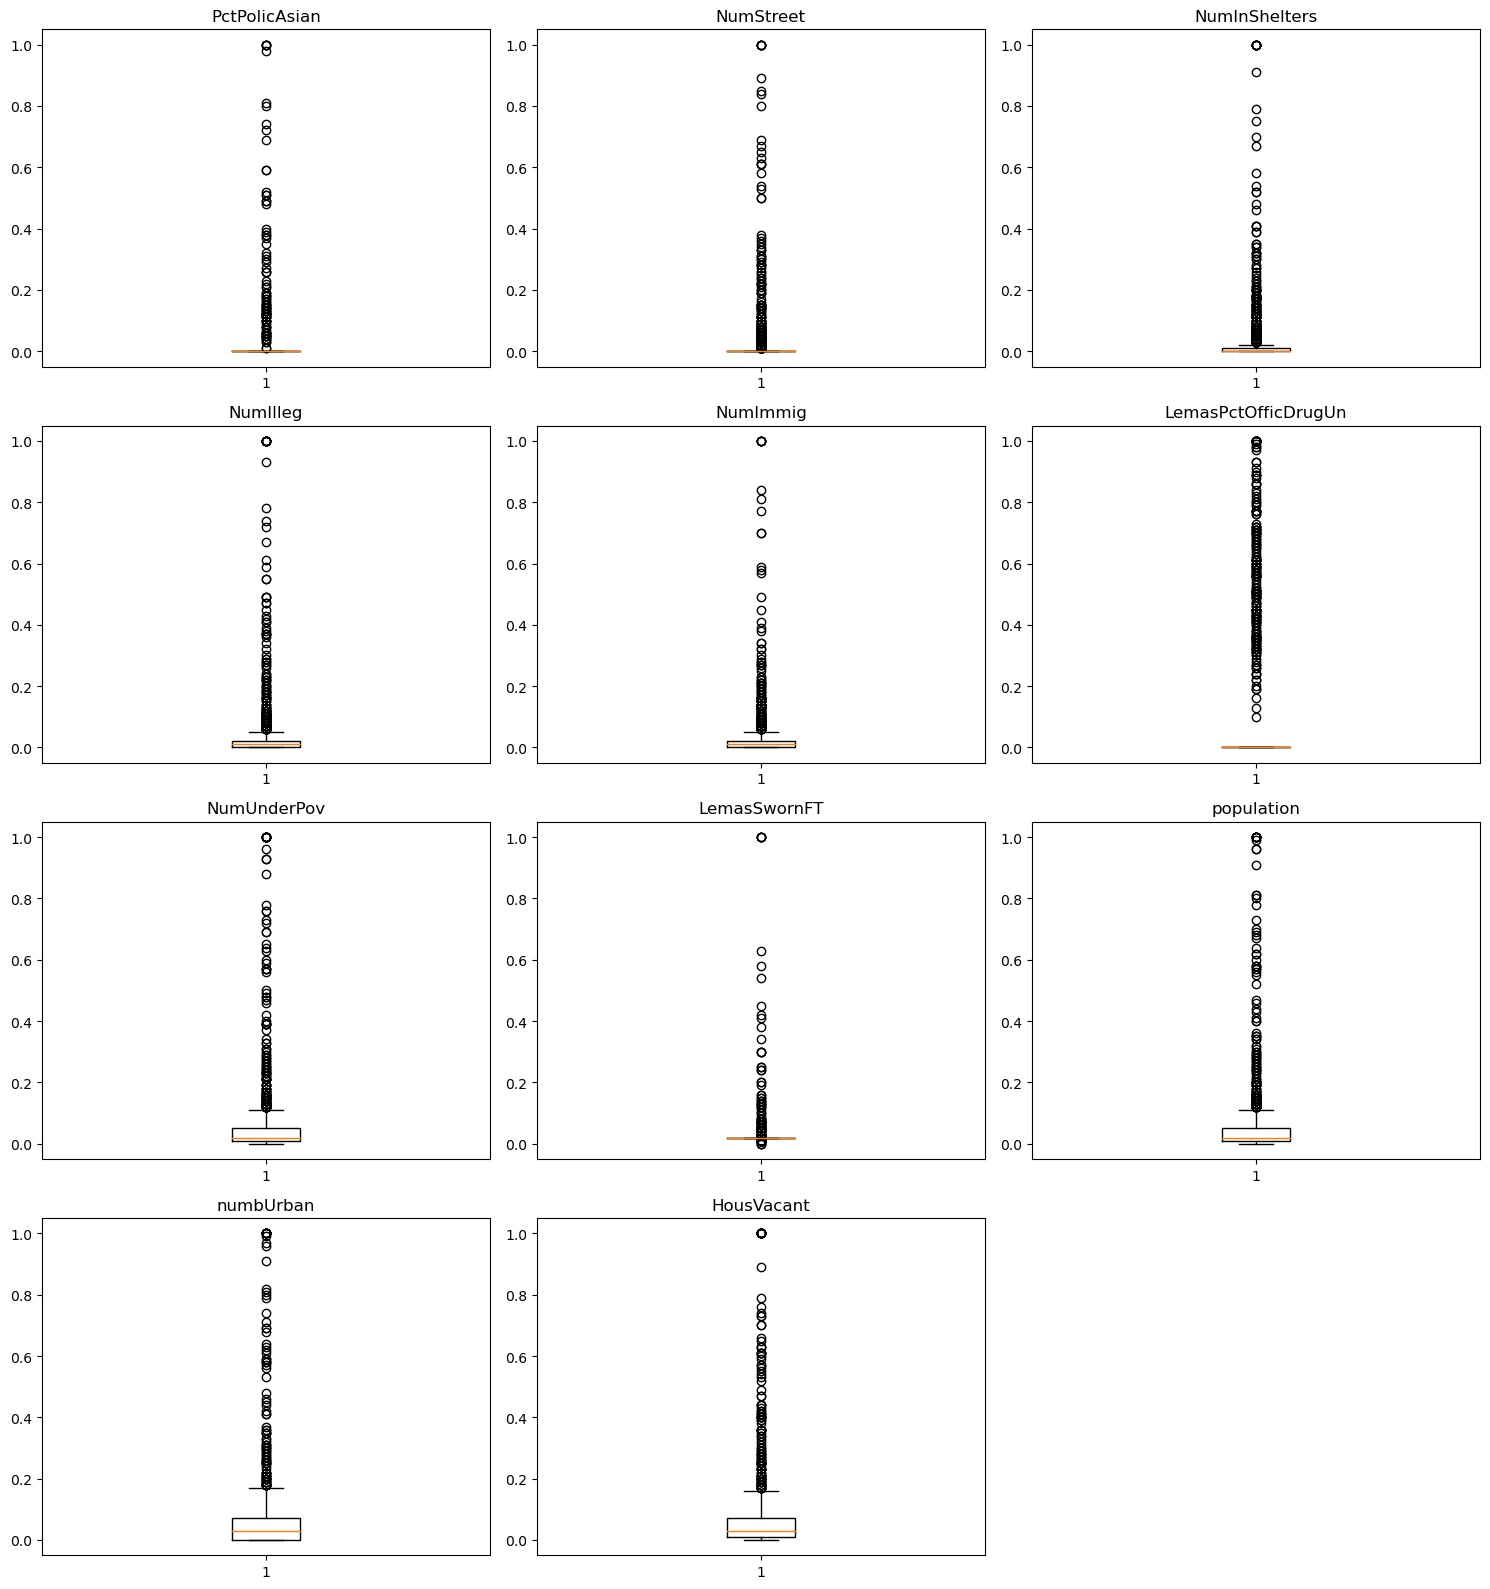

In [19]:
fig, axes = plt.subplots(
    4,
    3,
    figsize=(15, 16)
)

axes = axes.flatten()

for i, feature in enumerate(
    top_cv_features
):
    
    axes[i].boxplot(
        X_train[feature]
    )
    
    axes[i].set_title(
        feature
    )

for i in range(
    len(top_cv_features),
    len(axes)
):
    axes[i].axis('off')

plt.tight_layout()
plt.show()

The scatter plots can show possible relationships between the selected features and the response, as well as patterns and outliers. However, statistical significance cannot be determined from the scatter plots alone. A formal statistical test or regression model would be needed to determine whether a feature is statistically significant.

## 2(f)

In [20]:
linear_model = LinearRegression()

linear_model.fit(
    X_train,
    y_train
)

y_test_pred_linear = linear_model.predict(
    X_test
)

linear_test_mse = mean_squared_error(
    y_test,
    y_test_pred_linear
)

print(
    "Linear Regression Test MSE:",
    linear_test_mse
)

Linear Regression Test MSE: 0.017966215426067335


The test MSE for the least squares linear regression model is approximately 0.0180.

## 2(g)

In [21]:
ridge_alphas = np.logspace(
    -4,
    4,
    100
)

ridge_model = RidgeCV(
    alphas=ridge_alphas,
    cv=5,
    scoring='neg_mean_squared_error'
)

ridge_model.fit(
    X_train,
    y_train
)

y_test_pred_ridge = ridge_model.predict(
    X_test
)

ridge_test_mse = mean_squared_error(
    y_test,
    y_test_pred_ridge
)

print(
    "Best lambda:",
    ridge_model.alpha_
)

print(
    "Ridge Regression Test MSE:",
    ridge_test_mse
)

Best lambda: 2.310129700083163
Ridge Regression Test MSE: 0.017516249302564884


The best value of $\lambda$ selected by 5-fold cross-validation is approximately 2.3101.

The Ridge Regression test MSE is approximately 0.0175.

## 2(h)

In [22]:
lasso_model = LassoCV(
    cv=5,
    alphas=np.logspace(-4, 1, 100),
    max_iter=10000
)

lasso_model.fit(
    X_train,
    y_train
)

y_test_pred_lasso = lasso_model.predict(
    X_test
)

lasso_test_mse = mean_squared_error(
    y_test,
    y_test_pred_lasso
)

lasso_selected = X_train.columns[
    np.abs(lasso_model.coef_) > 1e-8
].tolist()

print(
    "Best lambda:",
    lasso_model.alpha_
)

print(
    "LASSO Test MSE:",
    lasso_test_mse
)

print(
    "Number of selected variables:",
    len(lasso_selected)
)

print(
    "Selected variables:"
)

for variable in lasso_selected:
    print(variable)

Best lambda: 0.0001261856883066021
LASSO Test MSE: 0.017615034821046878
Number of selected variables: 74
Selected variables:
racepctblack
racePctAsian
agePct12t21
agePct12t29
pctUrban
pctWWage
pctWFarmSelf
pctWInvInc
pctWSocSec
pctWPubAsst
pctWRetire
whitePerCap
blackPerCap
indianPerCap
AsianPerCap
OtherPerCap
HispPerCap
PctPopUnderPov
PctLess9thGrade
PctEmploy
PctEmplManu
PctOccupManu
MalePctDivorce
MalePctNevMarr
FemalePctDiv
PctKids2Par
PctYoungKids2Par
PctTeen2Par
PctWorkMom
NumIlleg
PctIlleg
NumImmig
PctImmigRecent
PctImmigRec10
PctRecImmig10
PctNotSpeakEnglWell
PctLargHouseOccup
PersPerOccupHous
PctPersOwnOccup
PctPersDenseHous
PctHousLess3BR
MedNumBR
HousVacant
PctHousOccup
PctVacantBoarded
PctVacMore6Mos
MedYrHousBuilt
PctHousNoPhone
PctWOFullPlumb
OwnOccLowQuart
RentLowQ
MedRent
MedRentPctHousInc
MedOwnCostPctInc
MedOwnCostPctIncNoMtg
NumInShelters
NumStreet
PctForeignBorn
PctBornSameState
PctSameCity85
LemasSwFTFieldPerPop
PolicReqPerOffic
RacialMatchCommPol
PctPolicBlack
Pct

In [23]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(
    X_train
)

X_test_scaled = scaler.transform(
    X_test
)

In [24]:
lasso_scaled_model = LassoCV(
    cv=5,
    alphas=np.logspace(-4, 1, 100),
    max_iter=10000
)

lasso_scaled_model.fit(
    X_train_scaled,
    y_train
)

y_test_pred_lasso_scaled = (
    lasso_scaled_model.predict(
        X_test_scaled
    )
)

lasso_scaled_test_mse = mean_squared_error(
    y_test,
    y_test_pred_lasso_scaled
)

lasso_scaled_selected = X_train.columns[
    np.abs(
        lasso_scaled_model.coef_
    ) > 1e-8
].tolist()

print(
    "Best lambda:",
    lasso_scaled_model.alpha_
)

print(
    "Standardized LASSO Test MSE:",
    lasso_scaled_test_mse
)

print(
    "Number of selected variables:",
    len(lasso_scaled_selected)
)

print(
    "Selected variables:"
)

for variable in lasso_scaled_selected:
    print(variable)

Best lambda: 0.0008111308307896872
Standardized LASSO Test MSE: 0.017670233667342737
Number of selected variables: 72
Selected variables:
racepctblack
racePctAsian
agePct12t21
agePct12t29
pctUrban
pctWWage
pctWFarmSelf
pctWInvInc
pctWSocSec
pctWPubAsst
pctWRetire
whitePerCap
blackPerCap
indianPerCap
AsianPerCap
OtherPerCap
HispPerCap
PctPopUnderPov
PctLess9thGrade
PctEmploy
PctEmplManu
MalePctDivorce
MalePctNevMarr
FemalePctDiv
PctKids2Par
PctYoungKids2Par
PctTeen2Par
PctWorkMom
NumIlleg
PctIlleg
NumImmig
PctImmigRec5
PctImmigRec10
PctRecImmig10
PctNotSpeakEnglWell
PctLargHouseOccup
PersPerOccupHous
PctPersOwnOccup
PctPersDenseHous
PctHousLess3BR
HousVacant
PctHousOccup
PctVacantBoarded
PctVacMore6Mos
MedYrHousBuilt
PctHousNoPhone
PctWOFullPlumb
RentLowQ
MedRent
MedRentPctHousInc
MedOwnCostPctInc
MedOwnCostPctIncNoMtg
NumInShelters
NumStreet
PctForeignBorn
PctSameCity85
LemasSwFTFieldPerPop
LemasTotalReq
PolicReqPerOffic
RacialMatchCommPol
PctPolicBlack
PctPolicHisp
PctPolicAsian
Offic

In [25]:
print(
    "LASSO Test MSE:",
    round(lasso_test_mse, 6)
)

print(
    "Standardized LASSO Test MSE:",
    round(lasso_scaled_test_mse, 6)
)

print(
    "Variables selected without standardization:",
    len(lasso_selected)
)

print(
    "Variables selected with standardization:",
    len(lasso_scaled_selected)
)

LASSO Test MSE: 0.017615
Standardized LASSO Test MSE: 0.01767
Variables selected without standardization: 74
Variables selected with standardization: 72


The LASSO model without additional standardization has a test MSE of 0.017615 and selects 74 variables.

After standardizing the features, the test MSE is 0.017670 and 72 variables are selected.

The two models have very similar test errors. The non-standardized LASSO performs slightly better because it has a lower test MSE, while the standardized model selects slightly fewer variables.

## 2(i)

In [26]:
pcr_pipeline = Pipeline([
    (
        'pca',
        PCA()
    ),
    (
        'linear',
        LinearRegression()
    )
])

component_values = list(
    range(
        1,
        X_train.shape[1] + 1
    )
)

pcr_grid = GridSearchCV(
    pcr_pipeline,
    param_grid={
        'pca__n_components': component_values
    },
    cv=5,
    scoring='neg_mean_squared_error'
)

pcr_grid.fit(
    X_train,
    y_train
)

GridSearchCV(cv=5,
             estimator=Pipeline(steps=[('pca', PCA()),
                                       ('linear', LinearRegression())]),
             param_grid={'pca__n_components': [1, 2, 3, 4, 5, 6, 7, 8, 9, 10,
                                               11, 12, 13, 14, 15, 16, 17, 18,
                                               19, 20, 21, 22, 23, 24, 25, 26,
                                               27, 28, 29, 30, ...]},
             scoring='neg_mean_squared_error')

In [27]:
best_M = pcr_grid.best_params_[
    'pca__n_components'
]

y_test_pred_pcr = pcr_grid.predict(
    X_test
)

pcr_test_mse = mean_squared_error(
    y_test,
    y_test_pred_pcr
)

print(
    "Best number of principal components:",
    best_M
)

print(
    "PCR Test MSE:",
    pcr_test_mse
)

Best number of principal components: 96
PCR Test MSE: 0.018339861732082626


The best PCR model uses 96 principal components, selected by 5-fold cross-validation.

The PCR test MSE is approximately 0.01834.

## 2(j)

In [28]:
alpha_values = np.logspace(
    -4,
    2,
    20
)

xgb_model = xgb.XGBRegressor(
    objective='reg:squarederror',
    n_estimators=500,
    max_depth=3,
    learning_rate=0.05,
    random_state=42,
    n_jobs=-1
)

xgb_grid = GridSearchCV(
    xgb_model,
    param_grid={
        'reg_alpha': alpha_values
    },
    cv=5,
    scoring='neg_mean_squared_error',
    n_jobs=-1
)

xgb_grid.fit(
    X_train,
    y_train
)

GridSearchCV(cv=5,
             estimator=XGBRegressor(base_score=None, booster=None,
                                    callbacks=None, colsample_bylevel=None,
                                    colsample_bynode=None,
                                    colsample_bytree=None, device=None,
                                    early_stopping_rounds=None,
                                    enable_categorical=False, eval_metric=None,
                                    feature_types=None, feature_weights=None,
                                    gamma=None, grow_policy=None,
                                    importance_type=None,
                                    interaction_constraints=None...
             param_grid={'reg_alpha': array([1.00000000e-04, 2.06913808e-04, 4.28133240e-04, 8.85866790e-04,
       1.83298071e-03, 3.79269019e-03, 7.84759970e-03, 1.62377674e-02,
       3.35981829e-02, 6.95192796e-02, 1.43844989e-01, 2.97635144e-01,
       6.15848211e-01, 1.27427499e+00, 2.63665090e+00, 5.45559478e+00,
       1.12883789e+01, 2.33572147e+01, 4.83293024e+01, 1.00000000e+02])},
             scoring='neg_mean_squared_error')

In [29]:
best_alpha = xgb_grid.best_params_[
    'reg_alpha'
]

y_test_pred_xgb = xgb_grid.predict(
    X_test
)

xgb_test_mse = mean_squared_error(
    y_test,
    y_test_pred_xgb
)

print(
    "Best alpha:",
    best_alpha
)

print(
    "XGBoost Test MSE:",
    xgb_test_mse
)

Best alpha: 2.6366508987303554
XGBoost Test MSE: 0.01609404100182871


The best value of $\alpha$ selected by 5-fold cross-validation is approximately 2.6367.

The XGBoost model has a test MSE of approximately 0.01609.